### 9. Multivariable Calculus and Gradients

Machine-learning models often depend on many parameters. Partial derivatives measure how an output changes when one input changes while the others are held fixed.

For $f(x, y) = x^2 + 3xy + y^2$:

$$
\frac{\partial f}{\partial x} = 2x + 3y, \qquad
\frac{\partial f}{\partial y} = 3x + 2y
$$

The gradient stacks partial derivatives into a vector.

In [1]:
import sympy as sp
x, y = sp.symbols('x y')
f = x**2 + 3*x*y + y**2
grad = [sp.diff(f, x), sp.diff(f, y)]
print("f(x,y) =", f)
print("Gradient =", grad)
print("At (1,2):", [g.subs({x:1, y:2}) for g in grad])

f(x,y) = x**2 + 3*x*y + y**2
Gradient = [2*x + 3*y, 3*x + 2*y]
At (1,2): [8, 7]


### Gradient intuition

The gradient points in the direction of steepest local increase. Its negative points toward steepest local decrease, which is why gradient descent uses:

$$
\theta_{t+1} = \theta_t - \eta \nabla L(\theta_t)
$$

where $\eta$ is the learning rate and $L$ is a loss function.

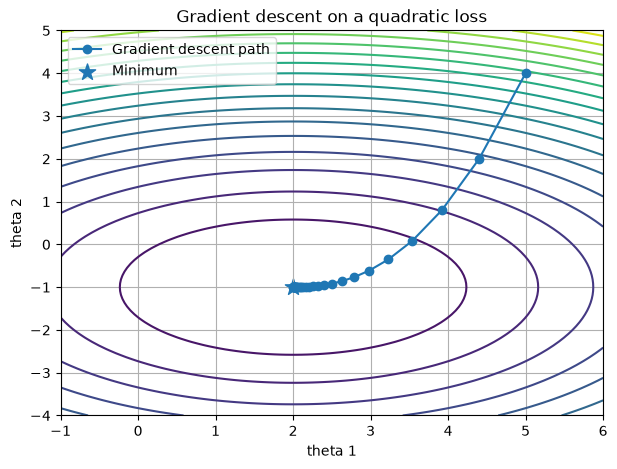

Final parameters: [ 2.00371382 -0.99999889]
Final loss: 1.3792462311476954e-05


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def loss(theta):
    return (theta[0]-2)**2 + 2*(theta[1]+1)**2

def grad_loss(theta):
    return np.array([2*(theta[0]-2), 4*(theta[1]+1)])

theta = np.array([5.0, 4.0])
learning_rate = 0.1
path = [theta.copy()]
for _ in range(30):
    theta = theta - learning_rate * grad_loss(theta)
    path.append(theta.copy())
path = np.array(path)

grid_x = np.linspace(-1, 6, 100)
grid_y = np.linspace(-4, 5, 100)
X, Y = np.meshgrid(grid_x, grid_y)
Z = (X-2)**2 + 2*(Y+1)**2

plt.figure(figsize=(7, 5))
plt.contour(X, Y, Z, levels=20)
plt.plot(path[:,0], path[:,1], "o-", label="Gradient descent path")
plt.scatter([2], [-1], marker="*", s=150, label="Minimum")
plt.xlabel("theta 1"); plt.ylabel("theta 2")
plt.title("Gradient descent on a quadratic loss")
plt.grid(True); plt.legend(); plt.show()
print("Final parameters:", theta)
print("Final loss:", loss(theta))

### Exercises
1. Find the gradient of f(x,y)=x²+y²+4x.
2. Calculate the gradient at (1,−2).
3. Explain how the learning rate affects gradient descent.
4. What can happen if the learning rate is too large?